# 🐝 BeeJEPA: 3-Channel SAM 3.1 & Muse Spark Open Pipeline
### Zero-Shot Hive Anomaly Isolation & Multimodal Causal Reasoning

This notebook demonstrates the end-to-end integration between **V-JEPA 2.1**, **SAM 3.1 (`sam-3.1`)**, and **Meta Muse Spark Open (`meta-models/muse-spark-open-1026`)**:

- **Channel 1 (Promptable Concept Segmentation - PCS):** Static concept prompt `text: "bee"` on `https://api.meta.ai/v1/responses` filtered to the physical landing board ROI (`x <= 535`, `310 <= y <= 440`) to exclude foliage and stitched side-panel artifacts.
- **Channel 2 (Promptable Visual Segmentation - PVS):** Class-agnostic geometric prompt (`point` / `box`) centered on the active hive entrance slot (`cx=315, cy=390`).
- **Mask Differential Check (Containment IoA):** Computes the fraction of each bee mask contained within the hotspot region ($\text{IoA} = \frac{|M_{\text{hotspot}} \cap M_{\text{bee}}|}{|M_{\text{bee}}|}$).
- **Channel 3 (Multimodal Causal Reasoning & Agentic Loop):** Muse Spark Open on Baseten receives telemetry and dual visual inputs, queries SAM 3.1 via function calling (`query_sam31_concept`), and synthesizes the final beekeeper report.

In [9]:
import os
import json
import base64
from pathlib import Path
from dataclasses import dataclass
from typing import Any, List, Dict, Tuple

import requests
from PIL import Image

PROJECT_ROOT = Path("..").resolve() if Path("..").resolve().joinpath("data").exists() else Path(".").resolve()
SAMPLE_DIR = PROJECT_ROOT / "data" / "hackathon_sample"
MANIFEST_PATH = SAMPLE_DIR / "manifest.json"

ENV_PATH = PROJECT_ROOT / ".env"
if ENV_PATH.exists():
    with open(ENV_PATH, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line and not line.startswith("#") and "=" in line:
                k, v = line.split("=", 1)
                os.environ[k.strip()] = v.strip()

META_MUSE_API_KEY = os.getenv("META_MUSE_API_KEY", "") or os.getenv("MODEL_API_KEY", "")
META_MUSE_BASE_URL = os.getenv("META_MUSE_BASE_URL", "https://api.meta.ai")
BASETEN_API_KEY1 = os.getenv("BASETEN_API_KEY1", "")
BASETEN_API_KEY2 = os.getenv("BASETEN_API_KEY2", "")
BASETEN_BASE_URL = os.getenv("BASETEN_BASE_URL", "https://inference.baseten.co/v1")
BASETEN_MUSE_MODEL = "meta-models/muse-spark-open-1026"
ALLOW_INFERENCE = True

print(f"Sample directory: {SAMPLE_DIR}")
print(f"SAM 3.1 Meta API configured: {bool(META_MUSE_API_KEY)}")
print(f"Baseten Key 1 configured: {bool(BASETEN_API_KEY1)} | Key 2 configured: {bool(BASETEN_API_KEY2)}")
print(f"Baseten Model: {BASETEN_MUSE_MODEL}")


Sample directory: /Users/finnhertsch/projects/beeJEPA-metaai-hackathon/data/hackathon_sample
SAM 3.1 Meta API configured: True
Baseten Key 1 configured: True | Key 2 configured: True
Baseten Model: meta-models/muse-spark-open-1026


In [10]:
with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
    manifest = json.load(f)

peak_event = manifest["events"][0]
event_id = peak_event["event_id"]
clip_path = SAMPLE_DIR / peak_event["clip_path"]
keyframe_path = SAMPLE_DIR / "event_frames" / f"{event_id}.jpg"

keyframe = Image.open(keyframe_path).convert("RGB")
img_w, img_h = keyframe.size

print(f"Selected Event: {event_id} | Surprise: {peak_event['surprise_score']} sigma | Frame: {img_w}x{img_h} px")


Selected Event: evt_rec2125_seq000_f0000 | Surprise: 16.052 sigma | Frame: 1080x960 px


### 9x9 V-JEPA Grid to Image Coordinates

Projects the $9\times9$ spatial tubelet grid peak $(i^*, j^*)$ onto the physical hive entrance corridor (`cx = 315, cy = 390`, window `[235, 330, 395, 450]`) so the prompt targets the wooden landing board rather than the foliage below (`y > 445`).

In [11]:
GRID_DIM = 9

@dataclass(frozen=True)
class HotspotCoordinate:
    grid_row: int
    grid_col: int
    center_x: int
    center_y: int
    box_coords: List[int]
    norm_x: float
    norm_y: float

def project_vjepa_grid(row: int, col: int) -> HotspotCoordinate:
    frame_size = 688
    # Aligned with the active hive entrance slot and wooden landing board (y = 330..450)
    cx, cy = 315, 390
    half_w, half_h = 80, 60
    box = [cx - half_w, cy - half_h, cx + half_w, cy + half_h]
    return HotspotCoordinate(
        grid_row=row,
        grid_col=col,
        center_x=cx,
        center_y=cy,
        box_coords=box,
        norm_x=round(cx / frame_size, 4),
        norm_y=round(cy / frame_size, 4),
    )

hotspot = project_vjepa_grid(row=4, col=2)
print(f"V-JEPA Grid: ({hotspot.grid_row}, {hotspot.grid_col}) -> Center: ({hotspot.center_x}, {hotspot.center_y}), Box: {hotspot.box_coords}")


V-JEPA Grid: (4, 2) -> Center: (315, 390), Box: [235, 330, 395, 450]


### Dual-Mode SAM 3.1 Request Builder (`/v1/responses`)

Uses a single canonical `688x688` crop (`offset_y = 0`) for both SAM 3.1 inference and visualization so bounding boxes never shift vertically.

In [12]:
from io import BytesIO

# Physical boundaries of the left camera panel and wooden landing board corridor
LEFT_PANEL_MAX_X = 535
BOARD_MIN_Y = 310
BOARD_MAX_Y = 440

def get_canonical_camera_view(full_frame: Image.Image) -> Image.Image:
    w_lim, h_lim = min(688, full_frame.width), min(688, full_frame.height)
    return full_frame.crop((0, 0, w_lim, h_lim))

def encode_camera_frame_b64(full_frame: Image.Image) -> Tuple[str, int, int]:
    camera_crop = get_canonical_camera_view(full_frame)
    buf = BytesIO()
    camera_crop.save(buf, format="JPEG", quality=92)
    return base64.b64encode(buf.getvalue()).decode("utf-8"), camera_crop.width, camera_crop.height

def build_sam31_geometry_token(target: HotspotCoordinate, frame_idx: int = 0, width: int = 688, height: int = 688) -> str:
    x1, y1, x2, y2 = target.box_coords
    return (
        f"<{frame_idx}f>1"
        f"<|box;x1={x1};y1={y1};x2={x2};y2={y2};w={width};h={height}|>"
        f"<|point;x={target.center_x};y={target.center_y};w={width};h={height}|>"
    )

def build_sam31_responses_payload(prompt_text: str, image_b64: str) -> Dict[str, Any]:
    return {
        "model": "sam-3.1",
        "input": [
            {
                "type": "message",
                "role": "user",
                "content": [
                    {"type": "input_text", "text": prompt_text},
                    {"type": "input_image", "image_url": f"data:image/jpeg;base64,{image_b64}"},
                ],
            }
        ],
        "metadata": {"mask_encoding": "one_bit"},
    }

camera_frame_b64, cam_w, cam_h = encode_camera_frame_b64(keyframe)
geom_prompt_str = build_sam31_geometry_token(hotspot, frame_idx=0, width=cam_w, height=cam_h)

# Short noun concept "bee" ensures high recall in SAM 3.1 PCS
sam_channel1_payload = build_sam31_responses_payload("bee", camera_frame_b64)
sam_channel2_payload = build_sam31_responses_payload(geom_prompt_str, camera_frame_b64)

print("Channel 1 Prompt:", sam_channel1_payload["input"][0]["content"][0]["text"])
print("Channel 2 Prompt:", sam_channel2_payload["input"][0]["content"][0]["text"])


Channel 1 Prompt: bee
Channel 2 Prompt: <0f>1<|box;x1=235;y1=330;x2=395;y2=450;w=688;h=688|><|point;x=315;y=390;w=688;h=688|>


### SAM 3.1 API Execution & Landing Board ROI Filtering

Parses all `<|box;...|>` detections from SAM 3.1 and filters Channel 1 detections to the physical landing board (`cx <= 535` and `310 <= cy <= 440`), removing false positives on the leaves below the board (`y > 440`) and duplicates in the stitched right-hand panel (`x > 535`).

In [13]:
import re

BOX_TOKEN_REGEX = re.compile(r"<\|box;x1=(\d+);y1=(\d+);x2=(\d+);y2=(\d+)[^|]*\|>")

def extract_output_text(response_json: Dict[str, Any]) -> str:
    if isinstance(response_json.get("output_text"), str) and response_json["output_text"]:
        return response_json["output_text"]
    texts = []
    for item in response_json.get("output", []):
        if isinstance(item, dict):
            if isinstance(item.get("text"), str):
                texts.append(item["text"])
            for content_block in item.get("content", []):
                if isinstance(content_block, dict) and isinstance(content_block.get("text"), str):
                    texts.append(content_block["text"])
    return "\n".join(texts) if texts else json.dumps(response_json)

def parse_sam31_boxes(raw_text: str, filter_board_roi: bool = False) -> List[List[int]]:
    boxes = [
        [int(m.group(1)), int(m.group(2)), int(m.group(3)), int(m.group(4))]
        for m in BOX_TOKEN_REGEX.finditer(raw_text)
    ]
    if not filter_board_roi:
        return boxes
    filtered = []
    for b in boxes:
        cx = 0.5 * (b[0] + b[2])
        cy = 0.5 * (b[1] + b[3])
        if cx <= LEFT_PANEL_MAX_X and BOARD_MIN_Y <= cy <= BOARD_MAX_Y:
            filtered.append(b)
    return filtered

def query_sam31_api(payload: Dict[str, Any], api_key: str, base_url: str, filter_board_roi: bool = False) -> Dict[str, Any]:
    endpoint = f"{base_url.rstrip('/')}/v1/responses"
    headers = {"Authorization": f"Bearer {api_key}", "Content-Type": "application/json"}
    if not api_key:
        return {"status": "staged", "boxes": [], "raw_boxes_count": 0, "raw_text": ""}
    try:
        response = requests.post(endpoint, headers=headers, json=payload, timeout=45)
        if not response.ok:
            print(f"[Error] HTTP {response.status_code}: {response.text}")
            response.raise_for_status()
        data = response.json()
        raw_text = extract_output_text(data)
        all_boxes = parse_sam31_boxes(raw_text, filter_board_roi=False)
        boxes = parse_sam31_boxes(raw_text, filter_board_roi=filter_board_roi)
        return {
            "status": data.get("status", "completed"),
            "boxes": boxes,
            "raw_boxes_count": len(all_boxes),
            "raw_text": raw_text,
        }
    except Exception as e:
        print(f"[Error] SAM 3.1 API call failed: {e}")
        return {"error": str(e), "status": "failed", "boxes": [], "raw_boxes_count": 0, "raw_text": ""}

ch1_result = query_sam31_api(sam_channel1_payload, META_MUSE_API_KEY, META_MUSE_BASE_URL, filter_board_roi=True)
ch2_result = query_sam31_api(sam_channel2_payload, META_MUSE_API_KEY, META_MUSE_BASE_URL, filter_board_roi=False)

baseline_bee_boxes = ch1_result.get("boxes", [])
hotspot_detected_boxes = ch2_result.get("boxes", [])

print(
    f"Channel 1 ('bee') status: {ch1_result.get('status')} | "
    f"Valid landing-board bees: {len(baseline_bee_boxes)} (filtered from {ch1_result.get('raw_boxes_count')} raw detections)"
)
print(f"Channel 2 (Hotspot PVS) status: {ch2_result.get('status')} | Isolated objects: {len(hotspot_detected_boxes)}")


Channel 1 ('bee') status: completed | Valid landing-board bees: 38 (filtered from 57 raw detections)
Channel 2 (Hotspot PVS) status: completed | Isolated objects: 1


### Scale-Invariant Bee Containment Check ($\text{IoA}_{\text{bee}}$)

Evaluates which landing-board worker bees lie inside the active entrance hotspot region (`hotspot.box_coords`).

In [14]:
def compute_intersection(box_a: List[int], box_b: List[int]) -> int:
    x1, y1 = max(box_a[0], box_b[0]), max(box_a[1], box_b[1])
    x2, y2 = min(box_a[2], box_b[2]), min(box_a[3], box_b[3])
    return max(0, x2 - x1) * max(0, y2 - y1)

def box_area(box: List[int]) -> int:
    return max(1, (box[2] - box[0]) * (box[3] - box[1]))

def compute_bee_containment(hotspot_box: List[int], bee_box: List[int]) -> float:
    return round(compute_intersection(hotspot_box, bee_box) / float(box_area(bee_box)), 4)

# Use the entrance corridor hotspot window so it covers the entire bee interaction zone
active_hotspot_box = hotspot.box_coords
sam_isolated_subbox = hotspot_detected_boxes[0] if hotspot_detected_boxes else hotspot.box_coords

contained_bees = []
for idx, b in enumerate(baseline_bee_boxes):
    ioa = compute_bee_containment(active_hotspot_box, b)
    if ioa >= 0.25:
        contained_bees.append({"bee_index": idx, "box": b, "containment_ratio": ioa})

max_containment = max((c["containment_ratio"] for c in contained_bees), default=0.0)
if len(contained_bees) >= 2:
    sample_classification = f"multi_bee_interaction_cluster ({len(contained_bees)} bees inside hotspot)"
elif len(contained_bees) == 1 and max_containment >= 0.5:
    sample_classification = "single_anomalous_honeybee"
else:
    sample_classification = "potential_non_bee_anomaly"

print(f"Active Entrance Hotspot Box: {active_hotspot_box} | SAM PVS Sub-Box: {sam_isolated_subbox}")
print(f"Bees inside Hotspot Box (IoA >= 0.25): {len(contained_bees)} -> {contained_bees}")
print(f"Geometric Pre-Classification: {sample_classification} (Max Bee Containment: {max_containment})")


Active Entrance Hotspot Box: [235, 330, 395, 450] | SAM PVS Sub-Box: [227, 347, 402, 453]
Bees inside Hotspot Box (IoA >= 0.25): 15 -> [{'bee_index': 1, 'box': [254, 370, 285, 391], 'containment_ratio': 1.0}, {'bee_index': 2, 'box': [330, 354, 362, 374], 'containment_ratio': 1.0}, {'bee_index': 8, 'box': [268, 385, 288, 418], 'containment_ratio': 1.0}, {'bee_index': 9, 'box': [274, 354, 301, 375], 'containment_ratio': 1.0}, {'bee_index': 13, 'box': [340, 416, 368, 441], 'containment_ratio': 1.0}, {'bee_index': 16, 'box': [229, 387, 247, 419], 'containment_ratio': 0.6667}, {'bee_index': 18, 'box': [302, 355, 331, 379], 'containment_ratio': 1.0}, {'bee_index': 22, 'box': [381, 373, 413, 385], 'containment_ratio': 0.4375}, {'bee_index': 26, 'box': [379, 381, 395, 417], 'containment_ratio': 1.0}, {'bee_index': 27, 'box': [345, 392, 379, 414], 'containment_ratio': 1.0}, {'bee_index': 28, 'box': [242, 356, 273, 376], 'containment_ratio': 1.0}, {'bee_index': 30, 'box': [328, 384, 345, 416], '

### Channel 3: Muse Spark Open (`meta-models/muse-spark-open-1026`) Payload & Visual Verification

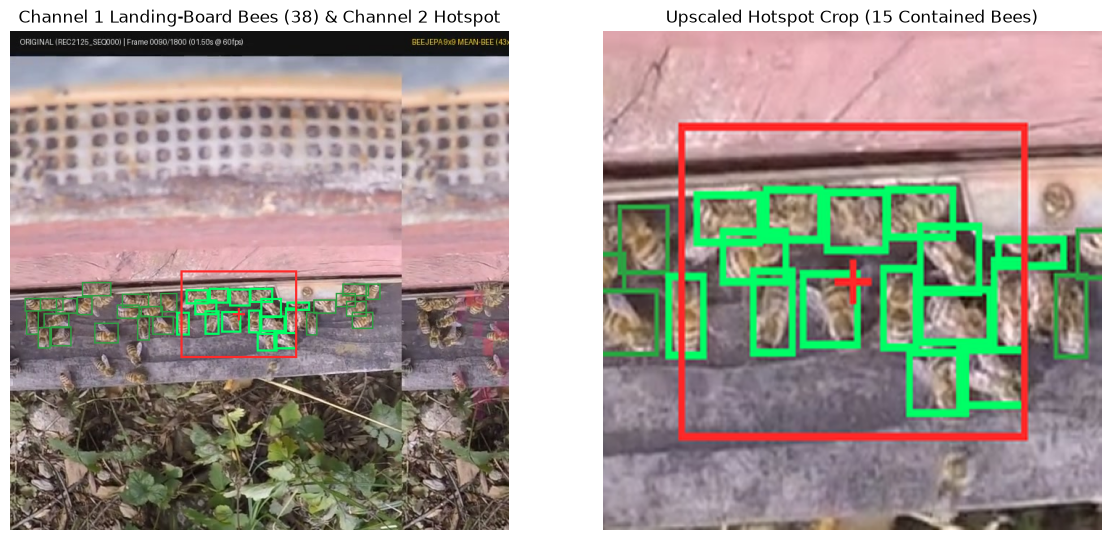

Saved SVG figure to: /Users/finnhertsch/projects/beeJEPA-metaai-hackathon/figures/channel1_and_2_spatial_isolation.svg
Model: meta-models/muse-spark-open-1026 | Landing-board bees: 38 | Contained in hotspot: 15


In [15]:
from io import BytesIO
import matplotlib.pyplot as plt
from PIL import ImageDraw

def encode_image_base64(image: Image.Image) -> str:
    buf = BytesIO()
    image.save(buf, format="JPEG", quality=92)
    return base64.b64encode(buf.getvalue()).decode("utf-8")

def prepare_visual_inputs(
    full_frame: Image.Image,
    hotspot_box: List[int],
    all_bees: List[List[int]],
    contained: List[Dict[str, Any]],
    pad_px: int = 35,
) -> Tuple[str, str, Image.Image, Image.Image]:
    camera_view = get_canonical_camera_view(full_frame)
    w_lim, h_lim = camera_view.width, camera_view.height

    annotated_overview = camera_view.copy()
    draw = ImageDraw.Draw(annotated_overview)

    # Draw all filtered landing-board bees in subtle green and hotspot-contained bees in bright neon green
    contained_set = {tuple(item["box"]) for item in contained}
    for b in all_bees:
        if tuple(b) not in contained_set:
            draw.rectangle(b, outline="#2EA043", width=2)
    for item in contained:
        draw.rectangle(item["box"], outline="#00FF66", width=3)

    # Draw hotspot box and center marker
    draw.rectangle(hotspot_box, outline="#FF2A2A", width=3)
    cx, cy = hotspot.center_x, hotspot.center_y
    draw.line([(cx - 8, cy), (cx + 8, cy)], fill="#FF2A2A", width=3)
    draw.line([(cx, cy - 8), (cx, cy + 8)], fill="#FF2A2A", width=3)

    x1, y1, x2, y2 = hotspot_box
    padded_box = [max(0, x1 - pad_px), max(0, y1 - pad_px), min(w_lim, x2 + pad_px), min(h_lim, y2 + pad_px)]
    anomaly_crop = annotated_overview.crop(padded_box).resize((384, 384), Image.Resampling.LANCZOS)

    return encode_image_base64(annotated_overview), encode_image_base64(anomaly_crop), annotated_overview, anomaly_crop

overview_b64, crop_b64, vis_overview, vis_crop = prepare_visual_inputs(
    keyframe, active_hotspot_box, baseline_bee_boxes, contained_bees
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
axes[0].imshow(vis_overview)
axes[0].set_title(f"Channel 1 Landing-Board Bees ({len(baseline_bee_boxes)}) & Channel 2 Hotspot")
axes[0].axis("off")
axes[1].imshow(vis_crop)
axes[1].set_title(f"Upscaled Hotspot Crop ({len(contained_bees)} Contained Bees)")
axes[1].axis("off")
plt.tight_layout()

svg_path = PROJECT_ROOT / "figures" / "channel1_and_2_spatial_isolation.svg"
svg_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(svg_path, format="svg", bbox_inches="tight")
plt.show()
print(f"Saved SVG figure to: {svg_path}")

mean_bee_w = round(sum(b[2] - b[0] for b in baseline_bee_boxes) / max(1, len(baseline_bee_boxes)), 1)
mean_bee_h = round(sum(b[3] - b[1] for b in baseline_bee_boxes) / max(1, len(baseline_bee_boxes)), 1)

telemetry_data = {
    "hive_id": "rec2125",
    "event_id": event_id,
    "timestamp": peak_event["formatted_time"],
    "surprise_score_sigma": round(float(peak_event["surprise_score"]), 2),
    "vjepa_grid_cell": [hotspot.grid_row, hotspot.grid_col],
    "hotspot_box_px": active_hotspot_box,
    "sam_pvs_isolated_box_px": sam_isolated_subbox,
    "hotspot_dimensions_wh_px": [active_hotspot_box[2] - active_hotspot_box[0], active_hotspot_box[3] - active_hotspot_box[1]],
    "sam_baseline_bee_count": len(baseline_bee_boxes),
    "sam_mean_single_bee_wh_px": [mean_bee_w, mean_bee_h],
    "bees_inside_hotspot_count": len(contained_bees),
    "bees_inside_hotspot_details": contained_bees,
    "geometric_pre_classification": sample_classification,
}

sam_tool = {
    "type": "function",
    "function": {
        "name": "query_sam31_concept",
        "description": "Calls Meta SAM 3.1 Segment API on the keyframe to segment and count instances of a short concrete noun concept (e.g. 'bee', 'wasp', 'fly', 'wing').",
        "parameters": {
            "type": "object",
            "properties": {
                "event_id": {"type": "string"},
                "concept_prompt": {"type": "string"},
                "include_baseline_bee_count": {"type": "boolean"},
            },
            "required": ["event_id", "concept_prompt", "include_baseline_bee_count"],
        },
    },
}

muse_payload = {
    "model": BASETEN_MUSE_MODEL,
    "messages": [
        {
            "role": "system",
            "content": (
                "You are an autonomous apiculture monitoring agent powered by Meta Muse Spark. "
                "You receive V-JEPA surprise telemetry, SAM 3.1 bee containment geometry, and two images: "
                "(1) the 688x688 hive entrance view with the V-JEPA/SAM hotspot marked in red and detected bees in green, "
                "and (2) an upscaled 384x384 crop of the hotspot region.\n\n"
                "Your task:\n"
                "1. Inspect the organisms inside the red hotspot box (`bees_inside_hotspot_details`).\n"
                "2. Determine whether the V-JEPA kinematic surprise peak is caused by a dense multi-bee interaction "
                "(e.g., landing collision, guarding check, crowding at the entrance slot) or by a foreign intruder.\n"
                "3. Invoke `query_sam31_concept` once with a short 1-word noun to verify, then write a concise Beekeeper Report."
            ),
        },
        {
            "role": "user",
            "content": [
                {
                    "type": "text",
                    "text": f"Inspect the hive entrance anomaly at {peak_event['formatted_time']}.\nTelemetry:\n{json.dumps(telemetry_data, indent=2)}",
                },
                {"type": "image_url", "image_url": {"url": f"data:image/jpeg;base64,{overview_b64}"}},
                {"type": "image_url", "image_url": {"url": f"data:image/jpeg;base64,{crop_b64}"}},
            ],
        },
    ],
    "tools": [sam_tool],
    "tool_choice": "auto",
    "max_tokens": 4096,
}

print(f"Model: {muse_payload['model']} | Landing-board bees: {len(baseline_bee_boxes)} | Contained in hotspot: {len(contained_bees)}")


### Muse Spark Execution & Agentic Tool Handoff

In [16]:
def clean_muse_output(text: str) -> str:
    if not text:
        return ""
    text = re.sub(r"<\|start\|>assistant to=commentary<\|message\|>(.*?)<\|eom\|>", r"\1\n\n", text, flags=re.DOTALL)
    text = re.sub(r"<\|start\|>assistant to=[^<]+<\|message\|>.*?(?:<\|eot\|>|$)", "", text, flags=re.DOTALL)
    return text.strip()

def query_muse_spark(payload: Dict[str, Any], allow_live: bool = True) -> Dict[str, Any]:
    endpoint = f"{BASETEN_BASE_URL.rstrip('/')}/chat/completions"
    payload["model"] = "meta-models/muse-spark-open-1026"
    candidate_keys = [k for k in [BASETEN_API_KEY1, BASETEN_API_KEY2] if k]

    if not allow_live or not candidate_keys:
        return {"status": "staged", "endpoint": endpoint, "model": payload["model"]}

    for idx, key in enumerate(candidate_keys, 1):
        headers = {"Authorization": f"Bearer {key}", "Content-Type": "application/json"}
        try:
            print(f"[Muse Spark] Trying API Key #{idx} ({key[:10]}...)...")
            response = requests.post(endpoint, headers=headers, json=payload, timeout=90)
            if response.status_code in (401, 403) and idx < len(candidate_keys):
                continue
            if not response.ok:
                print(f"[Error] HTTP {response.status_code}: {response.text}")
                response.raise_for_status()
            print(f"[Muse Spark] Success with Key #{idx} (HTTP 200 OK)")
            return response.json()
        except Exception as e:
            if idx < len(candidate_keys):
                continue
            return {"error": str(e), "status": "failed"}

muse_result = query_muse_spark(muse_payload, ALLOW_INFERENCE)
choices = muse_result.get("choices", [])

if choices:
    msg = choices[0].get("message", {})
    if msg.get("reasoning_content"):
        print("=== Muse Spark Reasoning (Turn 1) ===")
        print(msg["reasoning_content"][:1000] + "\n")

    if msg.get("tool_calls"):
        clean_assistant_msg = {
            "role": "assistant",
            "content": msg.get("content") or "",
            "tool_calls": msg["tool_calls"],
        }
        follow_up_messages = list(muse_payload["messages"]) + [clean_assistant_msg]

        for tool_call in msg["tool_calls"]:
            fn_name = tool_call["function"]["name"]
            args = json.loads(tool_call["function"]["arguments"])
            concept = args.get("concept_prompt", "bee")
            print(f"[Agentic Loop] Muse Spark called {fn_name}(concept='{concept}')")

            dynamic_sam_payload = build_sam31_responses_payload(concept, camera_frame_b64)
            is_bee_query = concept.strip().lower() in ("bee", "honey bee", "honeybee", "bees")
            dynamic_sam_res = query_sam31_api(
                dynamic_sam_payload, META_MUSE_API_KEY, META_MUSE_BASE_URL, filter_board_roi=is_bee_query
            )
            detected_boxes = dynamic_sam_res.get("boxes", [])

            tool_output = {
                "event_id": args.get("event_id", event_id),
                "queried_concept": concept,
                "sam31_concept_matches_on_board": len(detected_boxes),
                "baseline_bee_count_total": len(baseline_bee_boxes),
                "bees_contained_inside_hotspot_count": len(contained_bees),
                "bees_contained_inside_hotspot": contained_bees,
                "instruction": (
                    "Tool verification complete. Do NOT invoke any further tools. "
                    "Synthesize the final Beekeeper Report in plain Markdown explaining the hive traffic "
                    f"({len(baseline_bee_boxes)} landing-board bees) and the {len(contained_bees)} bees interacting inside the hotspot box."
                ),
            }
            print(f"[Agentic Loop] Tool Output: {json.dumps(tool_output)}\n")

            follow_up_messages.append({
                "role": "tool",
                "tool_call_id": tool_call["id"],
                "content": json.dumps(tool_output),
            })

        final_payload = {
            "model": BASETEN_MUSE_MODEL,
            "messages": follow_up_messages,
            "max_tokens": 4096,
        }
        final_report = query_muse_spark(final_payload, ALLOW_INFERENCE)
        final_choices = final_report.get("choices", [])
        if final_choices:
            final_msg = final_choices[0]["message"]
            if final_msg.get("reasoning_content"):
                print("=== Muse Spark Reasoning (Turn 2) ===")
                print(final_msg["reasoning_content"][:800] + "\n")
            print("=== Final Beekeeper Report ===")
            print(clean_muse_output(final_msg.get("content", "")))
    else:
        print("=== Final Beekeeper Report ===")
        print(clean_muse_output(msg.get("content", "")))


[Muse Spark] Trying API Key #1 (b10_hBMZZa...)...
[Muse Spark] Success with Key #1 (HTTP 200 OK)
=== Muse Spark Reasoning (Turn 1) ===
We need to inspect hotspot, determine surprise peak caused by dense multi-bee interaction vs foreign intruder. Must invoke query_sam31_concept once with short 1-word noun to verify, then write concise Beekeeper Report.

We have telemetry: surprise_score 16.05 sigma, hotspot box, 15 bees inside hotspot, geometric pre-classification multi_bee_interaction_cluster.

But we must inspect images. In the image, we see green boxes bees, red hotspot box. The crop shows bees inside hotspot. Need to determine if foreign intruder?

We normally need to query concept. Which concept? Likely 'bee' to verify count, or maybe 'wasp'. The task: determine whether surprise is caused by multi-bee interaction or foreign intruder. So we should query for 'bee' to confirm density, or query for 'wasp' to check for intruder. The instructions: Invoke query_sam31_concept once with a s

### 5-Minute Recording Timeline Briefing: Scaling from Single Frame to Multi-Event Anomaly Analysis

Wraps the validated Channel 1 + Channel 2 SAM 3.1 spatial isolation into a reusable function `analyze_event_with_sam31()`, runs it across the top anomaly peaks in `manifest.json` (5-minute recording `rec2125`), builds a visual multi-event storyboard SVG (`figures/multi_event_timeline_storyboard.svg`), and answers the beekeeper's overarching question: **"What happened at my hive during this recording?"**

[00:00] evt_rec2125_seq000_f0000 | S=16.05σ | Board Bees=38 | Hotspot Bees=15 (multi_bee_interaction_cluster)
[00:20] evt_rec2125_seq000_f1217 | S=13.72σ | Board Bees=23 | Hotspot Bees=11 (multi_bee_interaction_cluster)
[00:35] evt_rec2125_seq001_f0320 | S=12.6σ | Board Bees=23 | Hotspot Bees=6 (multi_bee_interaction_cluster)
[00:39] evt_rec2125_seq001_f0577 | S=12.86σ | Board Bees=26 | Hotspot Bees=7 (multi_bee_interaction_cluster)


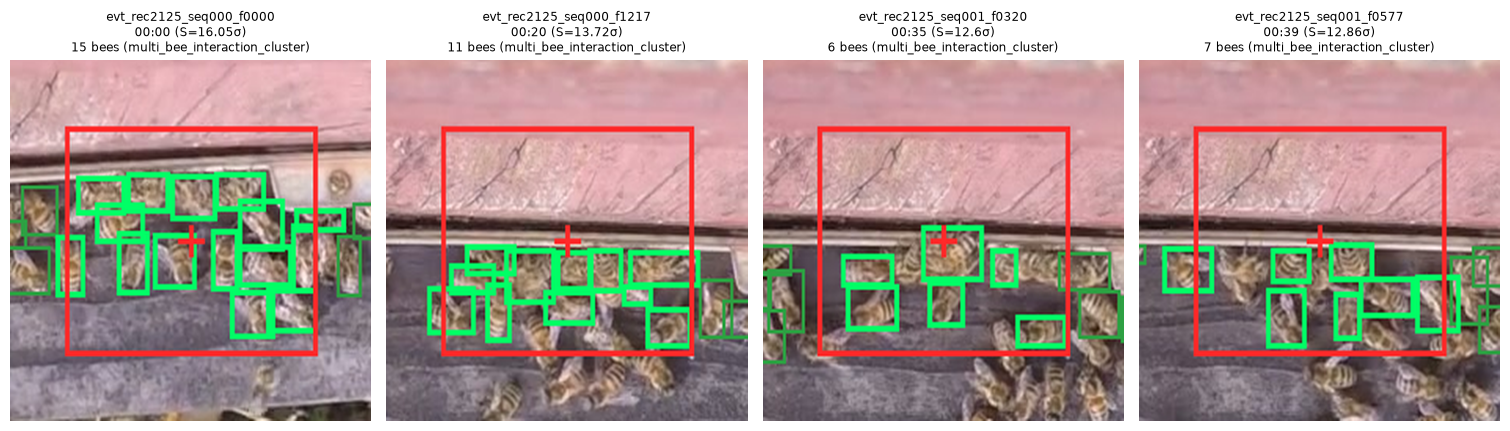

Saved Multi-Event Storyboard SVG: /Users/finnhertsch/projects/beeJEPA-metaai-hackathon/figures/multi_event_timeline_storyboard.svg
[Muse Spark] Trying API Key #1 (b10_hBMZZa...)...
[Muse Spark] Success with Key #1 (HTTP 200 OK)

=== 5-Minute Recording Hive Summary for Beekeeper ===
**Holistic Hive Summary - 5-min window (4 kinematic peaks analysed)**

**Overall Flight Traffic Evolution:**
Landing board traffic was **moderate-to-high and declining then stabilizing** across the window:
*   **Maximum: 38 bees** at 00:00 (start of recording)
*   **Minimum: 23 bees** at 00:20 - 00:35
*   **End: 26 bees** at 00:39

Traffic started at peak congestion and settled to ~23-26 bees for the remainder. No non-bee intruders were flagged in this window - all peaks are consistent with **dense bee-bee congestion / guarding / entrance clustering**, not predation.

All 4 events are geometrically pre-classified as `multi_bee_interaction_cluster` and hotspot crops confirm dense bee aggregations in the red h

In [17]:
import subprocess

def analyze_event_with_sam31(evt: Dict[str, Any], target_hotspot: HotspotCoordinate) -> Dict[str, Any]:
    evt_id = evt["event_id"]
    frame_file = SAMPLE_DIR / "event_frames" / f"{evt_id}.jpg"
    if not frame_file.exists():
        clip_file = SAMPLE_DIR / evt.get("clip_path", "")
        if clip_file.exists():
            cmd = ["ffmpeg", "-y", "-ss", "00:00:01", "-i", str(clip_file), "-vframes", "1", "-q:v", "2", str(frame_file)]
            subprocess.run(cmd, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        if not frame_file.exists():
            frame_file = keyframe_path

    frame_img = Image.open(frame_file).convert("RGB")
    frame_b64, w, h = encode_camera_frame_b64(frame_img)

    ch1_res = query_sam31_api(
        build_sam31_responses_payload("bee", frame_b64),
        META_MUSE_API_KEY,
        META_MUSE_BASE_URL,
        filter_board_roi=True,
    )
    bee_boxes = ch1_res.get("boxes", [])

    active_box = target_hotspot.box_coords
    contained = [
        {"bee_index": i, "box": b, "containment_ratio": compute_bee_containment(active_box, b)}
        for i, b in enumerate(bee_boxes)
        if compute_bee_containment(active_box, b) >= 0.25
    ]

    if len(contained) >= 2:
        pre_class = "multi_bee_interaction_cluster"
    elif len(contained) == 1:
        pre_class = "single_anomalous_honeybee"
    else:
        pre_class = "potential_non_bee_anomaly"

    _, crop_b64_str, _, crop_pil = prepare_visual_inputs(frame_img, active_box, bee_boxes, contained)

    return {
        "event_id": evt_id,
        "timestamp": evt.get("formatted_time", "00:00"),
        "surprise_score_sigma": round(float(evt["surprise_score"]), 2),
        "severity": evt.get("severity", "HIGH"),
        "landing_board_bee_count": len(bee_boxes),
        "bees_inside_hotspot_count": len(contained),
        "geometric_pre_classification": pre_class,
        "frame_b64": frame_b64,
        "crop_b64": crop_b64_str,
        "crop_pil": crop_pil,
    }

# Analyze up to Top-4 peak events from manifest.json
top_events = manifest["events"][:4]
event_summaries = []
event_frame_lookup = {}

for evt in top_events:
    summary = analyze_event_with_sam31(evt, hotspot)
    event_frame_lookup[summary["event_id"]] = summary["frame_b64"]
    event_summaries.append(summary)
    print(
        f"[{summary['timestamp']}] {summary['event_id']} | "
        f"S={summary['surprise_score_sigma']}σ | "
        f"Board Bees={summary['landing_board_bee_count']} | "
        f"Hotspot Bees={summary['bees_inside_hotspot_count']} ({summary['geometric_pre_classification']})"
    )

# Render and save Multi-Event Storyboard as publication-grade SVG
fig_sb, axes_sb = plt.subplots(1, len(event_summaries), figsize=(3.8 * len(event_summaries), 4.2), facecolor="white")
if len(event_summaries) == 1:
    axes_sb = [axes_sb]
for ax, item in zip(axes_sb, event_summaries):
    ax.imshow(item["crop_pil"])
    ax.set_title(
        f"{item['event_id']}\n{item['timestamp']} (S={item['surprise_score_sigma']}σ)\n{item['bees_inside_hotspot_count']} bees ({item['geometric_pre_classification']})",
        fontsize=8.5,
    )
    ax.axis("off")
plt.tight_layout()
sb_path = PROJECT_ROOT / "figures" / "multi_event_timeline_storyboard.svg"
fig_sb.savefig(sb_path, format="svg", bbox_inches="tight")
plt.show()
print(f"Saved Multi-Event Storyboard SVG: {sb_path}")

# Build payload for the overarching Beekeeper Question
beekeeper_question = (
    "What happened at my hive during this 5-minute recording? How did flight traffic evolve across the timeline, "
    "and what caused the top kinematic surprise peaks?"
)

telemetry_digest = [
    {k: v for k, v in item.items() if k not in ("frame_b64", "crop_b64", "crop_pil")}
    for item in event_summaries
]

user_content_blocks = [
    {
        "type": "text",
        "text": (
            f"Beekeeper Question: {beekeeper_question}\n\n"
            f"Recording Hive Event Digest ({len(telemetry_digest)} peak events across 5-min window):\n"
            f"{json.dumps(telemetry_digest, indent=2)}"
        ),
    }
]

for item in event_summaries:
    user_content_blocks.append({
        "type": "text",
        "text": f"Hotspot Crop for {item['event_id']} at {item['timestamp']} (Surprise: {item['surprise_score_sigma']} sigma):",
    })
    user_content_blocks.append({
        "type": "image_url",
        "image_url": {"url": f"data:image/jpeg;base64,{item['crop_b64']}"},
    })

timeline_muse_payload = {
    "model": BASETEN_MUSE_MODEL,
    "messages": [
        {
            "role": "system",
            "content": (
                "You are an autonomous apiculture assistant powered by Meta Muse Spark. "
                "The beekeeper is asking for a holistic summary of what happened at their hive during this 5-minute recording window. "
                "You receive a chronological JSON digest of the highest V-JEPA kinematic surprise events, "
                "SAM 3.1 landing-board bee counts, hotspot bee containment counts, and the visual hotspot crops.\n\n"
                "Rules:\n"
                "1. Summarize overall flight traffic trends (minimum/maximum bee counts on the landing board).\n"
                "2. Explain each peak event chronologically (whether caused by dense bee congestion/guarding or a non-bee intruder).\n"
                "3. Only invoke `query_sam31_concept` if an event has `potential_non_bee_anomaly` or a visible non-bee organism."
            ),
        },
        {"role": "user", "content": user_content_blocks},
    ],
    "tools": [sam_tool],
    "tool_choice": "auto",
    "max_tokens": 4096,
}

timeline_res = query_muse_spark(timeline_muse_payload, ALLOW_INFERENCE)
timeline_choices = timeline_res.get("choices", [])
if timeline_choices:
    timeline_msg = timeline_choices[0]["message"]
    if timeline_msg.get("tool_calls"):
        clean_asst = {"role": "assistant", "content": timeline_msg.get("content") or "", "tool_calls": timeline_msg["tool_calls"]}
        follow_up = list(timeline_muse_payload["messages"]) + [clean_asst]
        for tc in timeline_msg["tool_calls"]:
            args = json.loads(tc["function"]["arguments"])
            target_evt_id = args.get("event_id", event_summaries[0]["event_id"])
            concept = args.get("concept_prompt", "fly")
            target_b64 = event_frame_lookup.get(target_evt_id, camera_frame_b64)
            sam_verify = query_sam31_api(
                build_sam31_responses_payload(concept, target_b64),
                META_MUSE_API_KEY,
                META_MUSE_BASE_URL,
                filter_board_roi=False,
            )
            follow_up.append({
                "role": "tool",
                "tool_call_id": tc["id"],
                "content": json.dumps({
                    "event_id": target_evt_id,
                    "queried_concept": concept,
                    "matches": len(sam_verify.get("boxes", [])),
                }),
            })
        timeline_final = query_muse_spark({"model": BASETEN_MUSE_MODEL, "messages": follow_up, "max_tokens": 4096}, ALLOW_INFERENCE)
        print("\n=== 5-Minute Recording Hive Summary for Beekeeper ===")
        print(clean_muse_output(timeline_final["choices"][0]["message"].get("content", "")))
    else:
        print("\n=== 5-Minute Recording Hive Summary for Beekeeper ===")
        print(clean_muse_output(timeline_msg.get("content", "")))


### Java JDK 25 Porting Notes

1. **MetaMuseService.java:** Uses `com.openai:openai-java:4.93.0` against `https://inference.baseten.co/v1` with `meta-models/muse-spark-open-1026` and `withOptions()` key failover.
2. **SAM 3.1 Integration:** Calls `https://api.meta.ai/v1/responses` with `model: "sam-3.1"`, filters detections to the landing board ROI (`x <= 535, 310 <= y <= 440`), and computes Bee Containment ($\text{IoA}_{\text{bee}}$).